# Analysis and Visualization of Historical Rainfall Patterns in India Using Python

## Introduction

Rainfall is an important factor affecting agriculture, water resources, and the environment. Analysing historical rainfall data helps us understand rainfall patterns across different regions and years.

This project uses Python to analyse historical rainfall data in India. It includes data cleaning, numerical calculations, statistical analysis, data visualization, and web scraping.

## Objectives

1. To analyse historical rainfall data in India.
2. To clean and process rainfall data using Pandas.
3. To perform numerical calculations using NumPy.
4. To compare rainfall across months, years, and subdivisions.
5. To represent rainfall patterns using charts and graphs.
6. To retrieve rainfall-related information using web scraping.

## Dataset Details

**Dataset Name:** Rainfall in India (1901–2015)

**Source:** Kaggle — Rainfall in India by rajanand.

**Dataset Link:** https://www.kaggle.com/datasets/rajanand/rainfall-in-india

**Description:** The dataset contains historical rainfall records for different subdivisions of India. It includes monthly rainfall, annual rainfall, seasonal rainfall, and the corresponding years.

# Group Members-
### Vaibhav Bhalekar : B3-42
### Gargi Damkondwar : B3-44
### Ritvik Agrawal : B3-48
### Mayank Khode : B4-62

## Importing required libraries -

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup

In [3]:
file_path = "/content/rainfall in india 1901-2015.csv"
data = pd.read_csv(file_path)

## Understanding the dataset -

In [4]:
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])
display(data.head())

print("Column Names:")
print(data.columns.tolist())

print("\nDataset Information:")
data.info()

Number of rows: 4116
Number of columns: 19


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
0,ANDAMAN & NICOBAR ISLANDS,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,ANDAMAN & NICOBAR ISLANDS,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,ANDAMAN & NICOBAR ISLANDS,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6
3,ANDAMAN & NICOBAR ISLANDS,1904,9.4,14.7,0.0,202.4,304.5,495.1,502.0,160.1,820.4,222.2,308.7,40.1,3079.6,24.1,506.9,1977.6,571.0
4,ANDAMAN & NICOBAR ISLANDS,1905,1.3,0.0,3.3,26.9,279.5,628.7,368.7,330.5,297.0,260.7,25.4,344.7,2566.7,1.3,309.7,1624.9,630.8


Column Names:
['SUBDIVISION', 'YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'ANNUAL', 'Jan-Feb', 'Mar-May', 'Jun-Sep', 'Oct-Dec']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4116 entries, 0 to 4115
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SUBDIVISION  4116 non-null   object 
 1   YEAR         4116 non-null   int64  
 2   JAN          4112 non-null   float64
 3   FEB          4113 non-null   float64
 4   MAR          4110 non-null   float64
 5   APR          4112 non-null   float64
 6   MAY          4113 non-null   float64
 7   JUN          4111 non-null   float64
 8   JUL          4109 non-null   float64
 9   AUG          4112 non-null   float64
 10  SEP          4110 non-null   float64
 11  OCT          4109 non-null   float64
 12  NOV          4105 non-null   float64
 13  DEC          4106 non-null   float64
 14  ANNUAL       4090 

In [5]:
# We select one rainfall record and display its details
record = data.iloc[0]

print("Subdivision:", record['SUBDIVISION'])
print("Year:", record['YEAR'])
print("Annual Rainfall:", record['ANNUAL'], "mm")

Subdivision: ANDAMAN & NICOBAR ISLANDS
Year: 1901
Annual Rainfall: 3373.2 mm


In [ ]:
# Classifying rainfall according to the amount
print("Subdivision:", record["SUBDIVISION"], "| Year:", record["YEAR"], "| Annual rain:", rainfall, "mm")

rainfall = record['ANNUAL']

if pd.isna(rainfall):
    print("Annual rainfall data is not available.")
elif rainfall < 750:
    print("Rainfall Category: Low")
elif rainfall < 1500:
    print("Rainfall Category: Moderate")
else:
    print("Rainfall Category: High")

Subdivision: ANDAMAN & NICOBAR ISLANDS | Year: 1901 | Annual rain: 3373.2 mm
Rainfall Category: High


In [19]:
# Number of months with at least 100 mm rainfall
months = [
    'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN',
    'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC'
]

count = 0

for month in months:
    if pd.notna(record[month]) and record[month] >= 100:
        count += 1

print("Number of months with rainfall of at least 100 mm:", count)

Number of months with rainfall of at least 100 mm: 7


In [8]:
# Total recorded rainfall across the twelve months
total_rainfall = 0

for month in months:
    if pd.notna(record[month]):
        total_rainfall += record[month]

print("Sum of available monthly rainfall values:", total_rainfall, "mm")

Sum of available monthly rainfall values: 3373.1999999999994 mm


## Exploring dataset attributes-

In [20]:
# String operations on subdivision name

name = str(data.iloc[0]["SUBDIVISION"])

print("Original Name:", name)
print("Uppercase:", name.upper())
print("Lowercase:", name.lower())
print("Title Case:", name.title())
print("Length:", len(name))
print("Words:", name.split())

Original Name: ANDAMAN & NICOBAR ISLANDS
Uppercase: ANDAMAN & NICOBAR ISLANDS
Lowercase: andaman & nicobar islands
Title Case: Andaman & Nicobar Islands
Length: 25
Words: ['ANDAMAN', '&', 'NICOBAR', 'ISLANDS']


In [22]:
# We use Andaman & Nicobar Islands' monthly rainfall for the first available year
andaman = data[
    data["SUBDIVISION"].str.upper() == "ANDAMAN & NICOBAR ISLANDS"
]

record_andaman = andaman.iloc[0]

# Creating list of monthly rainfall

andaman_rainfall = []

for month in months:
    andaman_rainfall.append(record_andaman[month])

print("Monthly Rainfall:", andaman_rainfall)

print("First Three Months:", andaman_rainfall[:3])
print("Reversed List:", andaman_rainfall[::-1])

Monthly Rainfall: [np.float64(49.2), np.float64(87.1), np.float64(29.2), np.float64(2.3), np.float64(528.8), np.float64(517.5), np.float64(365.1), np.float64(481.1), np.float64(332.6), np.float64(388.5), np.float64(558.2), np.float64(33.6)]
First Three Months: [np.float64(49.2), np.float64(87.1), np.float64(29.2)]
Reversed List: [np.float64(33.6), np.float64(558.2), np.float64(388.5), np.float64(332.6), np.float64(481.1), np.float64(365.1), np.float64(517.5), np.float64(528.8), np.float64(2.3), np.float64(29.2), np.float64(87.1), np.float64(49.2)]


In [23]:
# Storing year and annual rainfall in a tuple

year = record_andaman["YEAR"]
rainfall = record_andaman["ANNUAL"]

rainfall_tuple = (year, rainfall)

print("Year and Annual Rainfall:", rainfall_tuple)
print("Year:", rainfall_tuple[0])
print("Annual Rainfall:", rainfall_tuple[1])
print("Tuple Length:", len(rainfall_tuple))

Year and Annual Rainfall: (np.int64(1901), np.float64(3373.2))
Year: 1901
Annual Rainfall: 3373.2
Tuple Length: 2


In [24]:
# Creating a set of unique subdivisions

subdivisions = set(data["SUBDIVISION"].dropna())

print("Total Unique Subdivisions:", len(subdivisions))

print("First Five Subdivisions:", sorted(subdivisions)[:5])

Total Unique Subdivisions: 36
First Five Subdivisions: ['ANDAMAN & NICOBAR ISLANDS', 'ARUNACHAL PRADESH', 'ASSAM & MEGHALAYA', 'BIHAR', 'CHHATTISGARH']


In [25]:
# Storing monthly rainfall in a dictionary

rainfall_dictionary = {}

for month in months:
    rainfall_dictionary[month] = record_andaman[month]

print("Monthly Rainfall Dictionary:")
print(rainfall_dictionary)

print("January Rainfall:", rainfall_dictionary["JAN"])
print("June Rainfall:", rainfall_dictionary["JUN"])
print("December Rainfall:", rainfall_dictionary["DEC"])

Monthly Rainfall Dictionary:
{'JAN': np.float64(49.2), 'FEB': np.float64(87.1), 'MAR': np.float64(29.2), 'APR': np.float64(2.3), 'MAY': np.float64(528.8), 'JUN': np.float64(517.5), 'JUL': np.float64(365.1), 'AUG': np.float64(481.1), 'SEP': np.float64(332.6), 'OCT': np.float64(388.5), 'NOV': np.float64(558.2), 'DEC': np.float64(33.6)}
January Rainfall: 49.2
June Rainfall: 517.5
December Rainfall: 33.6


## basic operations on rainfall data -

In [26]:
# Convert monthly rainfall into a NumPy array
andaman_array = np.array(andaman_rainfall, dtype=float)

print("Monthly Rainfall Array:")
print(andaman_array)

Monthly Rainfall Array:
[ 49.2  87.1  29.2   2.3 528.8 517.5 365.1 481.1 332.6 388.5 558.2  33.6]


In [27]:
# Display array properties
print("Number of Elements:", andaman_array.size)
print("Shape of Array:", andaman_array.shape)
print("Dimensions:", andaman_array.ndim)
print("Data Type:", andaman_array.dtype)

Number of Elements: 12
Shape of Array: (12,)
Dimensions: 1
Data Type: float64


In [28]:
# Access rainfall values using indexes
print("January Rainfall:", andaman_array[0])
print("June Rainfall:", andaman_array[5])
print("December Rainfall:", andaman_array[11])

January Rainfall: 49.2
June Rainfall: 517.5
December Rainfall: 33.6


In [29]:
# Display rainfall for the first three months
print("First Three Months:", andaman_array[:3])

# Display rainfall for the last three months
print("Last Three Months:", andaman_array[-3:])

First Three Months: [49.2 87.1 29.2]
Last Three Months: [388.5 558.2  33.6]


In [30]:
# Find maximum and minimum rainfall
print("Maximum Monthly Rainfall:", np.max(andaman_array))
print("Minimum Monthly Rainfall:", np.min(andaman_array))

Maximum Monthly Rainfall: 558.2
Minimum Monthly Rainfall: 2.3


In [31]:
# Calculate total and average monthly rainfall
print("Total Rainfall:", np.sum(andaman_array))
print("Average Monthly Rainfall:", np.mean(andaman_array))

Total Rainfall: 3373.2000000000003
Average Monthly Rainfall: 281.1


In [32]:
# Sort rainfall values in ascending order
sorted_rainfall = np.sort(andaman_array)

print("Sorted Rainfall:")
print(sorted_rainfall)

Sorted Rainfall:
[  2.3  29.2  33.6  49.2  87.1 332.6 365.1 388.5 481.1 517.5 528.8 558.2]


In [33]:
# Add 10 mm to each monthly rainfall value
print("Rainfall After Adding 10 mm:")
print(andaman_array + 10)

# Multiply each monthly rainfall value by 2
print("Rainfall After Multiplying by 2:")
print(andaman_array * 2)

Rainfall After Adding 10 mm:
[ 59.2  97.1  39.2  12.3 538.8 527.5 375.1 491.1 342.6 398.5 568.2  43.6]
Rainfall After Multiplying by 2:
[  98.4  174.2   58.4    4.6 1057.6 1035.   730.2  962.2  665.2  777.
 1116.4   67.2]


In [55]:
from scipy.stats import pearsonr

# Select June and July rainfall
rainfall_data = data[["JUN", "JUL"]].dropna()

# Calculate Pearson correlation
correlation, p_value = pearsonr(
    rainfall_data["JUN"],
    rainfall_data["JUL"]
)

print("Pearson Correlation:", correlation)
print("P-value:", p_value)

Pearson Correlation: 0.7412853933626063
P-value: 0.0


## Data Analysis -

In [34]:
# Display basic dataset information
print("Number of Rows:", data.shape[0])
print("Number of Columns:", data.shape[1])

print("\nColumn Names:")
print(data.columns.tolist())

print("\nFirst Five Records:")
display(data.head())

Number of Rows: 4116
Number of Columns: 19

Column Names:
['SUBDIVISION', 'YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'ANNUAL', 'Jan-Feb', 'Mar-May', 'Jun-Sep', 'Oct-Dec']

First Five Records:


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
0,ANDAMAN & NICOBAR ISLANDS,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,ANDAMAN & NICOBAR ISLANDS,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,ANDAMAN & NICOBAR ISLANDS,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6
3,ANDAMAN & NICOBAR ISLANDS,1904,9.4,14.7,0.0,202.4,304.5,495.1,502.0,160.1,820.4,222.2,308.7,40.1,3079.6,24.1,506.9,1977.6,571.0
4,ANDAMAN & NICOBAR ISLANDS,1905,1.3,0.0,3.3,26.9,279.5,628.7,368.7,330.5,297.0,260.7,25.4,344.7,2566.7,1.3,309.7,1624.9,630.8


In [35]:
# Count missing values in each column
print("Missing Values:")
print(data.isnull().sum())

Missing Values:
SUBDIVISION     0
YEAR            0
JAN             4
FEB             3
MAR             6
APR             4
MAY             3
JUN             5
JUL             7
AUG             4
SEP             6
OCT             7
NOV            11
DEC            10
ANNUAL         26
Jan-Feb         6
Mar-May         9
Jun-Sep        10
Oct-Dec        13
dtype: int64


In [36]:
# Select rainfall records for Andaman
andaman_data = data[
    data["SUBDIVISION"].str.upper() == "ANDAMAN & NICOBAR ISLANDS"
]

print("Andaman & Nicobar Islands Rainfall Data:")
display(andaman_data.head())

Andaman & Nicobar Islands Rainfall Data:


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
0,ANDAMAN & NICOBAR ISLANDS,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,ANDAMAN & NICOBAR ISLANDS,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,ANDAMAN & NICOBAR ISLANDS,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6
3,ANDAMAN & NICOBAR ISLANDS,1904,9.4,14.7,0.0,202.4,304.5,495.1,502.0,160.1,820.4,222.2,308.7,40.1,3079.6,24.1,506.9,1977.6,571.0
4,ANDAMAN & NICOBAR ISLANDS,1905,1.3,0.0,3.3,26.9,279.5,628.7,368.7,330.5,297.0,260.7,25.4,344.7,2566.7,1.3,309.7,1624.9,630.8


In [37]:
# Display rainfall data for the year 2010
year_data = data[data["YEAR"] == 2010]

print("Rainfall Data for 2010:")
display(year_data.head())

Rainfall Data for 2010:


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
104,ANDAMAN & NICOBAR ISLANDS,2010,101.7,8.0,0.7,12.5,319.0,448.9,521.9,563.8,263.3,402.4,268.5,246.4,3157.1,109.8,332.2,1797.8,917.3
201,ARUNACHAL PRADESH,2010,0.6,13.2,237.8,466.9,312.7,509.9,378.0,321.5,444.2,97.7,58.9,14.2,2855.7,13.9,1017.5,1653.6,170.9
316,ASSAM & MEGHALAYA,2010,0.5,3.1,99.6,389.3,393.4,569.7,415.1,387.0,318.3,116.2,11.6,7.6,2711.5,3.7,882.3,1690.2,135.3
431,NAGA MANI MIZO TRIPURA,2010,1.0,7.9,85.8,161.5,294.0,411.6,367.5,393.2,309.8,220.2,9.2,33.5,2295.2,8.9,541.4,1482.0,262.9
546,SUB HIMALAYAN WEST BENGAL & SIKKIM,2010,5.6,19.6,77.6,176.6,335.9,558.1,593.4,461.3,308.1,66.2,7.9,2.2,2612.3,25.2,590.0,1920.8,76.3


In [38]:
# Find the record with the highest annual rainfall
highest_rainfall = data.loc[data["ANNUAL"].idxmax()]

print("Subdivision:", highest_rainfall["SUBDIVISION"])
print("Year:", highest_rainfall["YEAR"])
print("Annual Rainfall:", highest_rainfall["ANNUAL"], "mm")

Subdivision: ARUNACHAL PRADESH
Year: 1948
Annual Rainfall: 6331.1 mm


In [39]:
# Calculate average annual rainfall
average_rainfall = data["ANNUAL"].mean()

print("Average Annual Rainfall:", average_rainfall, "mm")

Average Annual Rainfall: 1411.0088997555013 mm


In [40]:
# Display the five records with the highest annual rainfall
sorted_data = data.sort_values(
    by="ANNUAL", ascending=False
)

print("Top Five Records by Annual Rainfall:")
display(sorted_data[["SUBDIVISION", "YEAR", "ANNUAL"]].head())

Top Five Records by Annual Rainfall:


,SUBDIVISION,YEAR,ANNUAL
142,ARUNACHAL PRADESH,1948,6331.1
132,ARUNACHAL PRADESH,1938,6129.0
115,ARUNACHAL PRADESH,1921,5691.4
3602,COASTAL KARNATAKA,1961,5553.9
112,ARUNACHAL PRADESH,1918,5486.3


In [41]:
# Categorize annual rainfall
data["Rainfall_Category"] = "Moderate"

data.loc[data["ANNUAL"] < 750, "Rainfall_Category"] = "Low"

data.loc[data["ANNUAL"] >= 1500, "Rainfall_Category"] = "High"

data.loc[data["ANNUAL"].isnull(), "Rainfall_Category"] = "Unknown"

print("Rainfall Categories:")
display(data[["SUBDIVISION", "YEAR", "ANNUAL", "Rainfall_Category"]].head())

Rainfall Categories:


,SUBDIVISION,YEAR,ANNUAL,Rainfall_Category
0,ANDAMAN & NICOBAR ISLANDS,1901,3373.2,High
1,ANDAMAN & NICOBAR ISLANDS,1902,3520.7,High
2,ANDAMAN & NICOBAR ISLANDS,1903,2957.4,High
3,ANDAMAN & NICOBAR ISLANDS,1904,3079.6,High
4,ANDAMAN & NICOBAR ISLANDS,1905,2566.7,High


## Data Visualization -


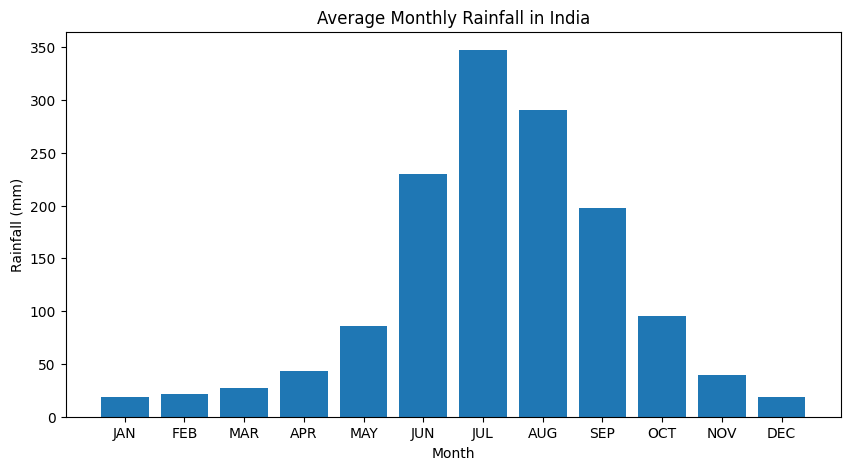

In [42]:
# Calculate average rainfall for each month
monthly_average = data[months].mean()

plt.figure(figsize=(10, 5))
plt.bar(months, monthly_average)

plt.title("Average Monthly Rainfall in India")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")

plt.show()

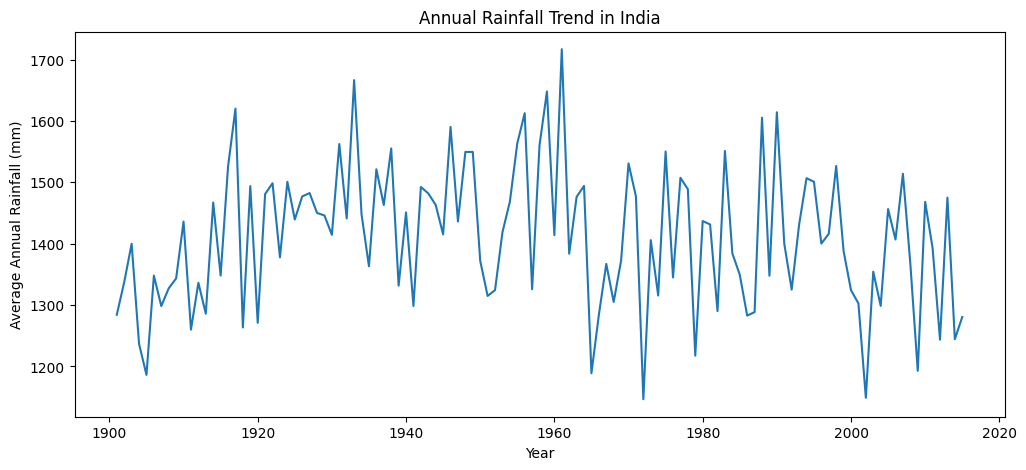

In [43]:
# Calculate average annual rainfall for each year
yearly_average = data.groupby("YEAR")["ANNUAL"].mean()

plt.figure(figsize=(12, 5))
plt.plot(yearly_average.index, yearly_average.values)

plt.title("Annual Rainfall Trend in India")
plt.xlabel("Year")
plt.ylabel("Average Annual Rainfall (mm)")

plt.show()

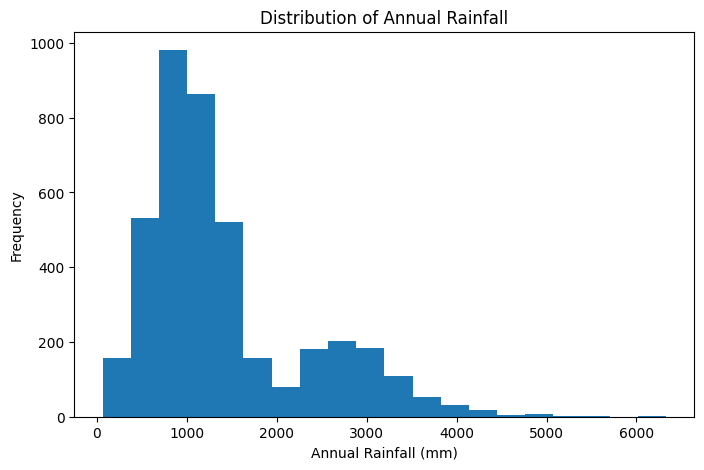

In [44]:
# Display distribution of annual rainfall
plt.figure(figsize=(8, 5))
plt.hist(data["ANNUAL"].dropna(), bins=20)

plt.title("Distribution of Annual Rainfall")
plt.xlabel("Annual Rainfall (mm)")
plt.ylabel("Frequency")

plt.show()

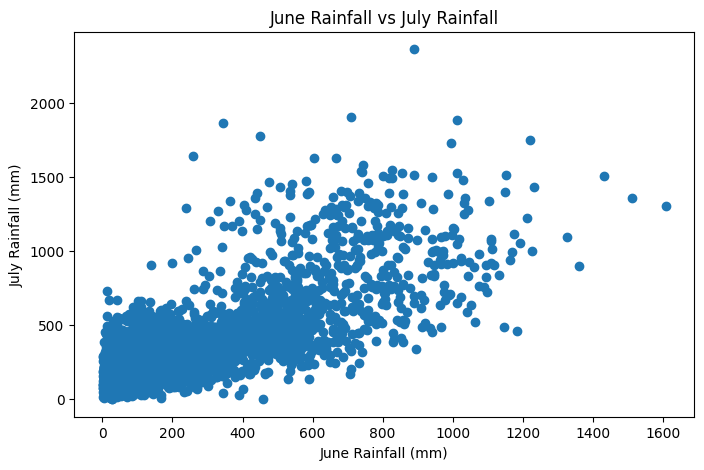

In [45]:
# Compare rainfall in June and July
plt.figure(figsize=(8, 5))
plt.scatter(data["JUN"], data["JUL"])

plt.title("June Rainfall vs July Rainfall")
plt.xlabel("June Rainfall (mm)")
plt.ylabel("July Rainfall (mm)")

plt.show()

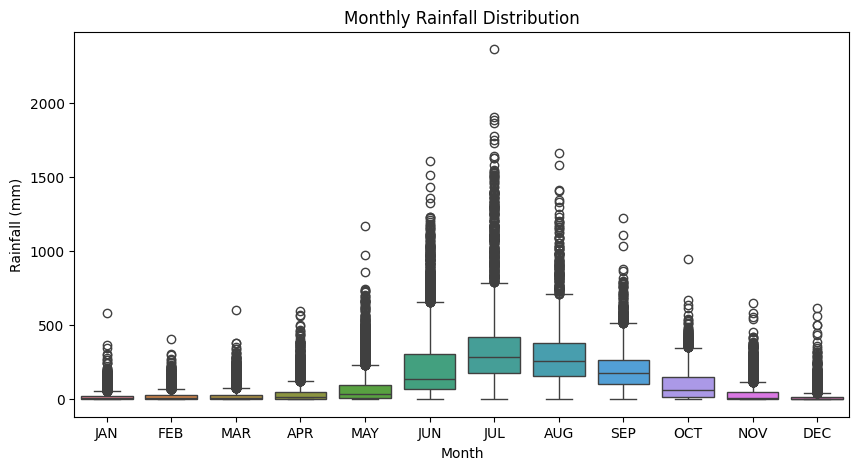

In [46]:
# Compare rainfall distributions across months
plt.figure(figsize=(10, 5))
sns.boxplot(data=data[months])

plt.title("Monthly Rainfall Distribution")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")

plt.show()

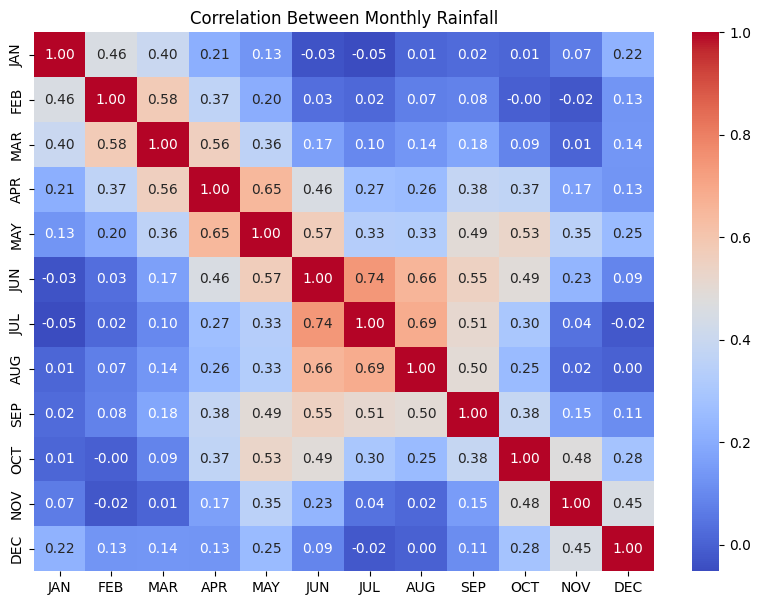

In [47]:
# Display correlation between monthly rainfall values
correlation = data[months].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Between Monthly Rainfall")
plt.show()

## Web Scraping -

In [49]:
import requests
from bs4 import BeautifulSoup

In [71]:
# Open the rainfall information webpage
url = "https://iced.niti.gov.in/climate-and-environment/climate-variability/rainfall"

response = requests.get(url)
print("Website Status Code:", response.status_code)

Website Status Code: 200


In [59]:
# Extract the title of the webpage
soup = BeautifulSoup(response.text, "html.parser")

if soup.title:
    print("Website Title:", soup.title.get_text(strip=True))
else:
    print("Website title not found.")

Website Title: Rainfall in India | Kaggle


In [61]:
# Extract headings from the webpage
headings = soup.find_all(["h1", "h2", "h3"])

print("Website Headings:")

for heading in headings:
    print(heading.get_text(strip=True))

Website Headings:


In [62]:
# Extract links from the webpage
links = soup.find_all("a")

print("First 10 Website Links:")

count = 0

for link in links:
    text = link.get_text(strip=True)
    address = link.get("href")

    if address:
        print(text, "-", address)
        count += 1

    if count == 10:
        break

First 10 Website Links:


In [69]:
# Find tables in the webpage HTML
tables = soup.find_all("table")

print("Number of Tables Found:", len(tables))

Number of Tables Found: 0
